<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/QuantumNetSec_VQC_DDoS_CICIDS2017.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QuantumNetSec: a variational quantum classifier for DDoS detection

This notebook re-implements the method of

> D. de Abreu, D. Moura, C. E. Rothenberg and A. Abelém, "QuantumNetSec: Quantum Machine Learning for Network Security," *International Journal of Network Management*, vol. 35, no. 4, e70018, 2025. https://doi.org/10.1002/nem.70018

The journal paper extends the authors' conference paper, "QML-IDS: Quantum Machine Learning Intrusion Detection System" ([arXiv:2410.16308](https://arxiv.org/abs/2410.16308)). Neither paper publishes code, so there is no official repository to build on. Everything below is written from the method as the papers describe it, using the same software stack (Qiskit, scikit-learn, TensorFlow) and the same set of quantum building blocks.

The notebook downloads CIC-IDS-2017 itself, trains a variational quantum classifier (VQC) to separate DDoS flows from benign traffic, and then repeats the paper's comparisons: QSVM and QCNN, three classical baselines, a 4 × 4 × 4 hyperparameter study, the five IBM devices under simulated noise, and per-attack multiclass F1.

**Runtime.** With `FAST_MODE = False` a full run takes about an hour on a two-core CPU (the standard free Colab runtime), most of it in the hyperparameter study and the one-vs-rest QCNN. `FAST_MODE = True` cuts sample sizes and iteration budgets so the whole notebook finishes in under 10 minutes, which suits a live class demo; its scores are lower and noisier. Running the full version before class and presenting the saved outputs works well. No GPU is needed.

## What follows the paper and what had to be chosen

The paper fixes the pipeline, the model families, the circuit libraries and the evaluation metric. It does not report qubit counts, feature reduction, sample sizes, train/test split, circuit repetitions, iteration budgets or shot counts. Where the paper is silent, this notebook makes a choice and says so in the code comments (look for `# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| Pipeline | Monitoring → feature extraction → preprocessing → classical-to-quantum mapping → hybrid QML → output interpretation → alert | Same seven steps, one section each |
| Datasets | UNSW-NB15, CIC-IDS-2017, CICIoT2023 | CIC-IDS-2017 only (the DDoS use case) |
| Quantum models | VQC, QSVM, QCNN | VQC, QSVM (QSVC), QCNN |
| Feature maps | PauliFeatureMap, RawFeatureVector, ZFeatureMap, ZZFeatureMap | All four |
| Ansätze | EfficientSU2, ExcitationPreserving, RealAmplitudes, TwoLocal | All four |
| Optimizers | COBYLA, ADAM, SPSA, GradientDescent | All four |
| Transpilation / error handling | Optimization level 0–3, resilience 0/1, dynamical decoupling 0/1 | Levels 0–3 and dynamical decoupling on noise models of the paper's devices; resilience emulated with readout-error correction; real-hardware cell uses IBM Runtime options |
| Backends | QASM simulator, IBM Cairo, Kyoto, Brisbane, Osaka, Sherbrooke | Aer simulator plus Qiskit's fake versions of the same five devices (stored calibration snapshots, not live machines) |
| Classical baselines | RF, SVM (scikit-learn), CNN (TensorFlow) | Same |
| Metric | F1 score, binary and per attack class | Same |
| Qubits | Not reported (Fig. 1 circuits show 4) | 4 |
| Feature reduction | Not reported | Standardise → PCA to 4 components → rescale to [0, π] |
| Sample sizes, split, reps, maxiter, shots | Not reported | Set in the configuration cell |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships TensorFlow, scikit-learn and pandas.
!pip -q install "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc

import importlib.util, subprocess, sys
if importlib.util.find_spec("tensorflow") is None:      # CNN baseline; preinstalled on most Colab images
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "tensorflow-cpu"], check=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.

In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: small budgets, whole notebook in under 10 minutes

SEED      = 42
N_QUBITS  = 4              # CHOICE: the paper does not report qubit counts; its Fig. 1 circuits use 4

# Binary task (BENIGN vs DDoS)
N_TRAIN, N_TEST = (120, 200) if FAST_MODE else (400, 400)
VQC_MAXITER      = 40  if FAST_MODE else 150     # CHOICE
QCNN_MAXITER     = 40  if FAST_MODE else 150     # CHOICE

# Hyperparameter study (paper Table I)
RUN_FULL_GRID    = False   # True: all 64 feature-map x ansatz x optimizer combinations (about 1.5-2 h)
GRID_TRAIN, GRID_VAL, GRID_MAXITER = (60, 100, 25) if FAST_MODE else (150, 150, 50)
GRAD_TRAIN, GRAD_MAXITER = (20, 5) if FAST_MODE else (40, 15)   # ADAM / GradientDescent use parameter-shift gradients, which are slow on CPU

# Noisy-device study (paper Tables II-III)
NOISY_N_TEST = 60 if FAST_MODE else 200
SHOTS        = 1024        # CHOICE

# Multiclass task (paper Table VI, CIC-IDS-17 column)
RUN_MULTICLASS        = True
MC_PER_CLASS          = 40 if FAST_MODE else 80   # flows sampled per attack family (60 % train / 40 % test)
MC_VQC_MAXITER        = 40 if FAST_MODE else 150
RUN_QCNN_MULTICLASS   = not FAST_MODE             # one-vs-rest QCNN: 7 trainings, about 10 min
MC_QCNN_MAXITER       = 60

# Optional: run the trained VQC on real IBM hardware (needs a free IBM Quantum Platform API key)
IBM_TOKEN    = ""          # paste your key here, or leave empty to skip
IBM_INSTANCE = None        # optional CRN of your instance

DATA_DIR = "cicids2017"

In [3]:
import os, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import (z_feature_map, zz_feature_map, pauli_feature_map,
                                    real_amplitudes, efficient_su2, excitation_preserving, n_local, XGate)
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager, PassManager, Target
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling
from qiskit_aer.primitives import SamplerV2 as AerSampler

from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.circuit.library import raw_feature_vector
from qiskit_machine_learning.algorithms import VQC, QSVC, NeuralNetworkClassifier
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA, SPSA, ADAM, GradientDescent

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1


## 1. Network monitoring and data collection

The paper's first step is capturing traffic. Here that step is replaced by the public CIC-IDS-2017 capture from the Canadian Institute for Cybersecurity (Sharafaldin, Habibi Lashkari and Ghorbani, ICISSP 2018). Each row is one bidirectional flow summarised by CICFlowMeter, labelled BENIGN or with an attack name.

The binary task uses the Friday-afternoon file, which contains the LOIC DDoS attack against the victim web server alongside normal traffic. The download comes from a public Hugging Face mirror of UNB's `MachineLearningCSV` files; UNB's own site now puts the files behind a registration form. If the mirror is unreachable, the code falls back to a GitHub copy of the same day, which keeps every flow and label but only 26 of the 78 flow features.

In [4]:
import requests

HF_BASE = "https://huggingface.co/datasets/c01dsnap/CIC-IDS2017/resolve/main/"
FALLBACK = {  # reduced-column copy, used only if the mirror is unreachable
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv":
        "https://raw.githubusercontent.com/StarterArcher/CICIDS2017/master/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
}

def download(fname, data_dir=DATA_DIR):
    # Download one CIC-IDS-2017 day file, trying the mirror first and the fallback second.
    os.makedirs(data_dir, exist_ok=True)
    path = os.path.join(data_dir, fname)
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000:
        print(f"already present: {fname}")
        return path
    for url in [HF_BASE + fname, FALLBACK.get(fname)]:
        if url is None:
            continue
        try:
            print(f"downloading {fname} from {url.split('/')[2]} ...", end=" ", flush=True)
            with requests.get(url, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(path + ".part", "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            os.replace(path + ".part", path)
            print(f"{os.path.getsize(path)/1e6:.1f} MB")
            return path
        except Exception as e:
            print(f"failed ({e.__class__.__name__})")
    raise RuntimeError(f"could not download {fname}")

DDOS_FILE = download("Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")

downloading Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv from huggingface.co ... 77.1 MB


## 2. Feature extraction and 3. data preprocessing

CICFlowMeter has already extracted the flow statistics. Preprocessing follows what the paper lists (normalisation and handling of missing values) and adds the steps a quantum model needs:

1. Drop identifiers (IP addresses, ports, timestamps). They describe the lab network, not the attack, and a model that learns them would not transfer.
2. Replace infinite rates (division by a zero-length flow) with missing values and drop those rows; drop exact duplicates.
3. Draw a class-balanced sample. A statevector simulation costs time per sample, so the quantum models see hundreds of flows, not hundreds of thousands.
4. Fit the scaler and PCA on the training split only, then apply them to the test split, so no information from test flows leaks into training.
5. Reduce to `N_QUBITS` principal components (one feature per qubit) and rescale each to [0, π], the range of a rotation angle.

In [5]:
ID_COLUMNS = ["Flow ID", "Source IP", "Src IP", "Source Port", "Src Port", "Destination IP", "Dst IP",
              "Destination Port", "Dst Port", "Timestamp"]   # CHOICE: ports dropped as lab-specific identifiers

def load_flows(path):
    # Read one day file and return a cleaned DataFrame with numeric features and a Label column.
    df = pd.read_csv(path, encoding="latin-1", low_memory=False)
    df.columns = df.columns.str.strip()
    df = df.drop(columns=[c for c in ID_COLUMNS if c in df.columns])
    df["Label"] = df["Label"].astype(str).str.strip()
    feats = df.columns.drop("Label")
    df[feats] = df[feats].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
    return df

flows = load_flows(DDOS_FILE)
FEATURES = [c for c in flows.columns if c != "Label"]
print(f"{len(flows):,} clean flows, {len(FEATURES)} features")
print(flows["Label"].value_counts().to_string())

221,264 clean flows, 77 features
Label
DDoS      128014
BENIGN     93250


train (400, 4) test (400, 4)
variance kept by 4 components: 63.2%


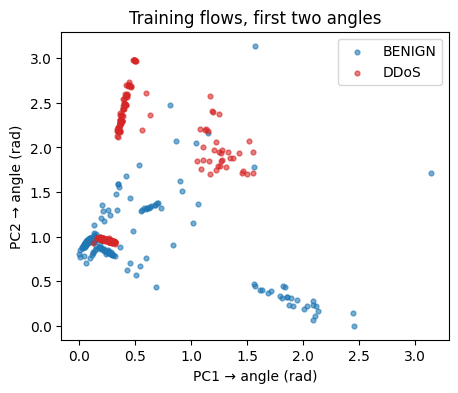

In [6]:
# Class-balanced sample, then a stratified train/test split
per_class = (N_TRAIN + N_TEST) // 2
sample = flows.groupby("Label").sample(n=per_class, random_state=SEED)
X_all = sample[FEATURES].to_numpy(float)
y_all = (sample["Label"] != "BENIGN").astype(int).to_numpy()      # 1 = DDoS (attack), 0 = benign

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all, train_size=N_TRAIN, test_size=N_TEST, stratify=y_all, random_state=SEED)

# Fitted on training data only
to_qubits = make_pipeline(StandardScaler(), PCA(n_components=N_QUBITS, random_state=SEED),
                          MinMaxScaler(feature_range=(0, np.pi)))
X_train = to_qubits.fit_transform(X_train_raw)
X_test  = np.clip(to_qubits.transform(X_test_raw), 0, np.pi)

pca = to_qubits.named_steps["pca"]
print("train", X_train.shape, "test", X_test.shape)
print("variance kept by", N_QUBITS, "components:", f"{pca.explained_variance_ratio_.sum():.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
for lab, name, c in [(0, "BENIGN", "tab:blue"), (1, "DDoS", "tab:red")]:
    m = y_train == lab
    ax.scatter(X_train[m, 0], X_train[m, 1], s=12, alpha=.6, label=name, c=c)
ax.set_xlabel("PC1 → angle (rad)"); ax.set_ylabel("PC2 → angle (rad)"); ax.legend(); ax.set_title("Training flows, first two angles")
plt.show()

## 4. Classical-to-quantum mapping: the four feature maps

A feature map $U_\phi(x)$ writes a classical vector $x$ into a quantum state $|\phi(x)\rangle = U_\phi(x)|0\rangle^{\otimes q}$. The paper tests the four maps in Qiskit's circuit library:

- **ZFeatureMap**: Hadamards followed by single-qubit phase rotations $P(2x_i)$. No entanglement, so each feature stays on its own qubit.
- **ZZFeatureMap**: adds two-qubit $ZZ$ phase terms $(\pi - x_i)(\pi - x_j)$, which entangle features. This is the map used in Havlíček et al. (Nature, 2019).
- **PauliFeatureMap**: the general form, where you choose the Pauli strings. The paper does not say which strings it used; this notebook uses `["Y", "ZZ"]` so that it differs from ZZFeatureMap (whose strings are `["Z", "ZZ"]`).
- **RawFeatureVector**: amplitude encoding. The normalised feature vector becomes the state's amplitudes, so 4 features need only $\log_2 4 = 2$ qubits.

ZFeatureMap: 4 qubits, 4 input parameters


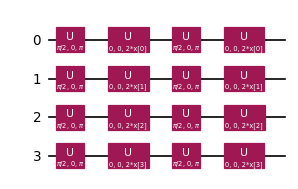

ZZFeatureMap: 4 qubits, 4 input parameters


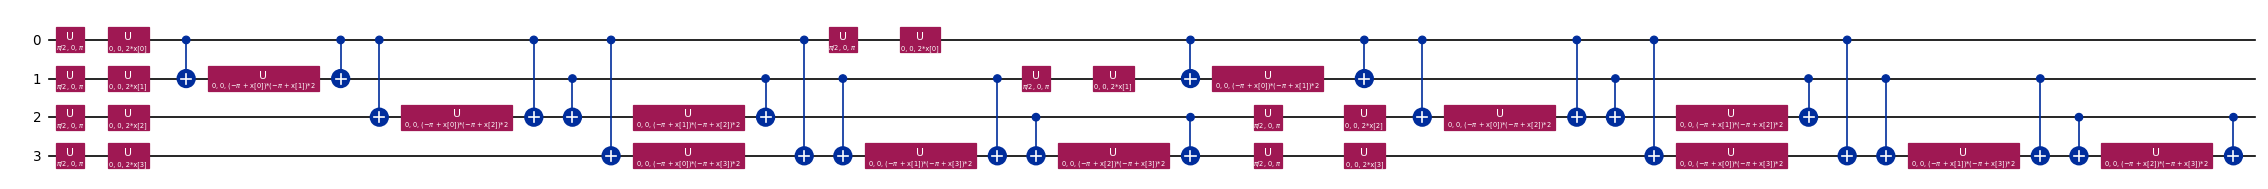

PauliFeatureMap: 4 qubits, 4 input parameters


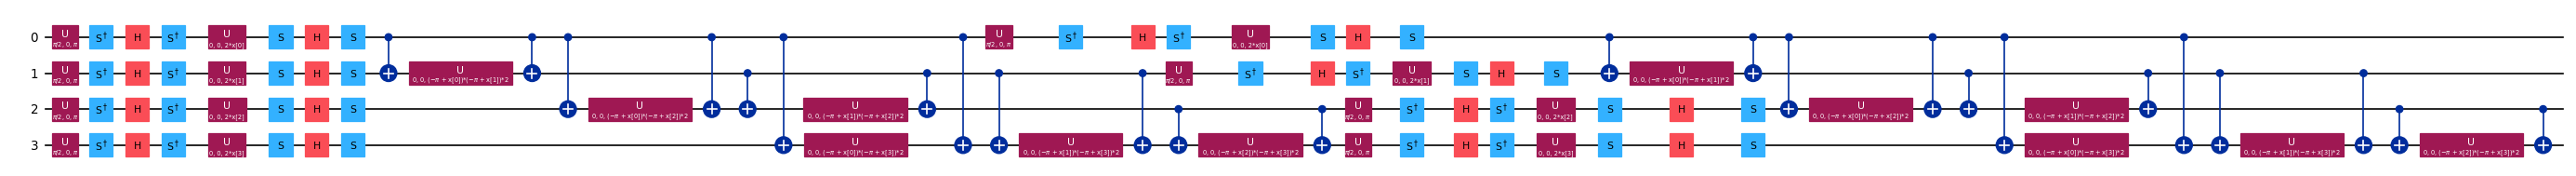

RawFeatureVector: 2 qubits, 4 input parameters


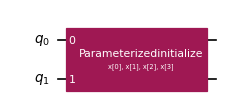

In [7]:
FEATURE_MAPS = ["ZFeatureMap", "ZZFeatureMap", "PauliFeatureMap", "RawFeatureVector"]
ANSATZE      = ["RealAmplitudes", "EfficientSU2", "ExcitationPreserving", "TwoLocal"]
OPTIMIZERS   = ["COBYLA", "SPSA", "ADAM", "GradientDescent"]

def build_feature_map(name, n=N_QUBITS):
    if name == "ZFeatureMap":      return z_feature_map(n, reps=2)                         # CHOICE: reps=2
    if name == "ZZFeatureMap":     return zz_feature_map(n, reps=2)
    if name == "PauliFeatureMap":  return pauli_feature_map(n, reps=2, paulis=["Y", "ZZ"])  # CHOICE: Pauli strings
    if name == "RawFeatureVector": return raw_feature_vector(n)                            # n features -> log2(n) qubits
    raise ValueError(name)

def build_ansatz(name, n):
    if name == "RealAmplitudes":       return real_amplitudes(n, reps=3)                    # CHOICE: reps
    if name == "EfficientSU2":         return efficient_su2(n, reps=2)
    if name == "ExcitationPreserving":   # its "Interaction" gate is rewritten into gates the Aer simulator knows
        return transpile(excitation_preserving(n, reps=2), basis_gates=["rz", "rx", "ry", "cx", "h", "p"], optimization_level=0)
    if name == "TwoLocal":             return n_local(n, ["ry", "rz"], "cz", reps=3)
    raise ValueError(name)

def build_optimizer(name, maxiter):
    if name == "COBYLA":          return COBYLA(maxiter=maxiter)
    if name == "SPSA":            return SPSA(maxiter=maxiter)
    if name == "ADAM":            return ADAM(maxiter=maxiter, lr=0.05)                     # CHOICE: learning rates
    if name == "GradientDescent": return GradientDescent(maxiter=maxiter, learning_rate=0.1)
    raise ValueError(name)

for name in FEATURE_MAPS:
    fm = build_feature_map(name)
    print(f"{name}: {fm.num_qubits} qubits, {fm.num_parameters} input parameters")
    display(fm.decompose().draw("mpl", fold=-1, scale=0.6) if name != "RawFeatureVector" else fm.draw("mpl", scale=0.6))

## 5. Hybrid QML processing: the variational quantum classifier

The VQC appends a trainable circuit $U(\theta)$, the ansatz, to the feature map and measures every qubit:

$$|\psi(x,\theta)\rangle = U(\theta)\,U_\phi(x)\,|0\rangle^{\otimes q}.$$

Qiskit's `VQC` reads the class from the measured bitstring's parity (an odd number of 1s means class 1), so $p(y=1\mid x)$ is the probability of an odd-parity outcome. A classical optimiser then adjusts $\theta$ to minimise the cross-entropy between these probabilities and the true labels. The quantum computer prepares and measures states; all learning happens on the classical side.

The first model uses a common default configuration (ZZFeatureMap + RealAmplitudes + COBYLA). Section 5b searches the paper's full hyperparameter space.

RealAmplitudes ansatz: 16 trainable angles


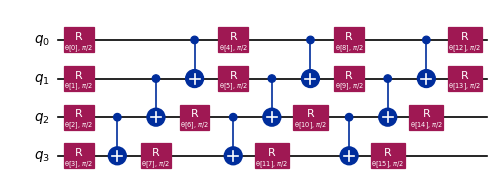

In [8]:
def make_live_plot(title, every=5):
    # Return (callback, history). The callback redraws the loss curve every few evaluations.
    history = []
    def callback(weights, loss):
        history.append(loss)
        if len(history) % every == 0:
            clear_output(wait=True)
            plt.figure(figsize=(6, 3)); plt.plot(history); plt.xlabel("optimizer evaluation")
            plt.ylabel("cross-entropy loss"); plt.title(title); plt.show()
    return callback, history

def make_vqc(fm_name, an_name, opt_name, maxiter, callback=None):
    fm = build_feature_map(fm_name)
    an = build_ansatz(an_name, fm.num_qubits)
    # Aer cannot simulate RawFeatureVector's ParameterizedInitialize instruction, so that map uses Qiskit's reference sampler
    sampler = (StatevectorSampler(default_shots=SHOTS, seed=SEED) if fm_name == "RawFeatureVector"
               else AerSampler(default_shots=SHOTS, seed=SEED))
    return VQC(feature_map=fm, ansatz=an, optimizer=build_optimizer(opt_name, maxiter), callback=callback, sampler=sampler)

ansatz_demo = build_ansatz("RealAmplitudes", N_QUBITS)
print("RealAmplitudes ansatz:", ansatz_demo.num_parameters, "trainable angles")
display(ansatz_demo.decompose().draw("mpl", fold=-1, scale=0.6))

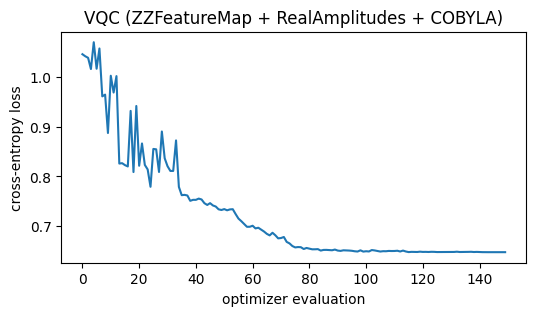

trained in 300 s | test F1 (DDoS = positive) = 0.7929


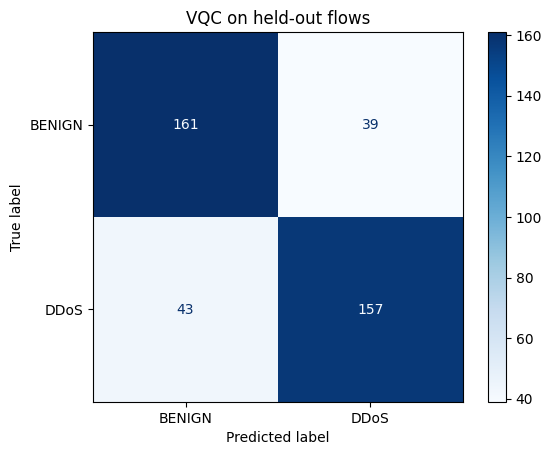

In [9]:
cb, hist = make_live_plot("VQC (ZZFeatureMap + RealAmplitudes + COBYLA)")
vqc = make_vqc("ZZFeatureMap", "RealAmplitudes", "COBYLA", VQC_MAXITER, callback=cb)
t0 = time.time(); vqc.fit(X_train, y_train); t_vqc = time.time() - t0

y_pred_vqc = vqc.predict(X_test)
print(f"trained in {t_vqc:.0f} s | test F1 (DDoS = positive) = {f1_score(y_test, y_pred_vqc):.4f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_vqc), display_labels=["BENIGN", "DDoS"]).plot(cmap="Blues")
plt.title("VQC on held-out flows"); plt.show()

### 6–7. Output interpretation and alert generation

The paper's last two steps turn the measured class into an alert. The cell below shows this for a few test flows: the measured odd-parity probability is the model's DDoS score, and a score above 0.5 raises an alert.

In [10]:
proba = vqc.predict_proba(X_test[:8])
for i, p in enumerate(proba):
    verdict = "ALERT: DDoS" if p[1] >= 0.5 else "ok"
    truth = "DDoS" if y_test[i] else "BENIGN"
    print(f"flow {i}: p(DDoS) = {p[1]:.2f} -> {verdict:12s} (true label: {truth})")

flow 0: p(DDoS) = 0.17 -> ok           (true label: BENIGN)
flow 1: p(DDoS) = 0.71 -> ALERT: DDoS  (true label: DDoS)
flow 2: p(DDoS) = 0.80 -> ALERT: DDoS  (true label: DDoS)
flow 3: p(DDoS) = 0.79 -> ALERT: DDoS  (true label: DDoS)
flow 4: p(DDoS) = 0.39 -> ok           (true label: DDoS)
flow 5: p(DDoS) = 0.61 -> ALERT: DDoS  (true label: BENIGN)
flow 6: p(DDoS) = 0.74 -> ALERT: DDoS  (true label: DDoS)
flow 7: p(DDoS) = 0.34 -> ok           (true label: BENIGN)


## 5d. Quantum convolutional neural network

The QCNN follows the construction in Qiskit's QCNN tutorial (after Cong, Choi and Lukin, *Nature Physics*, 2019). A convolution layer applies the same parametrised two-qubit block to neighbouring pairs; a pooling layer then folds half of the qubits into the other half. With 4 qubits the circuit runs conv → pool (4 → 2) → conv → pool (2 → 1), and the class is read from $\langle Z\rangle$ on the last remaining qubit: positive means BENIGN, negative means DDoS after mapping labels to ±1.

QCNN ansatz: 24 trainable angles


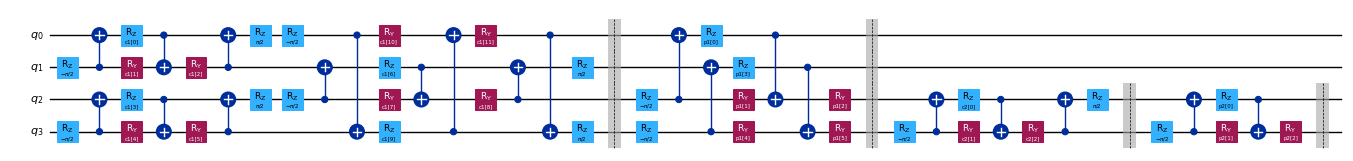

In [13]:
def conv_block(p):
    qc = QuantumCircuit(2)
    qc.rz(-np.pi / 2, 1); qc.cx(1, 0); qc.rz(p[0], 0); qc.ry(p[1], 1)
    qc.cx(0, 1); qc.ry(p[2], 1); qc.cx(1, 0); qc.rz(np.pi / 2, 0)
    return qc

def pool_block(p):
    qc = QuantumCircuit(2)
    qc.rz(-np.pi / 2, 1); qc.cx(1, 0); qc.rz(p[0], 0); qc.ry(p[1], 1); qc.cx(0, 1); qc.ry(p[2], 1)
    return qc

def conv_layer(n, prefix):
    q = list(range(n))
    pairs = [(0, 1)] if n == 2 else list(zip(q[0::2], q[1::2])) + list(zip(q[1::2], q[2::2] + [0]))
    params = ParameterVector(prefix, 3 * len(pairs)); qc = QuantumCircuit(n)
    for k, (a, b) in enumerate(pairs):
        qc.compose(conv_block(params[3 * k:3 * k + 3]), [a, b], inplace=True)
    qc.barrier(); return qc

def pool_layer(n, prefix):
    half = n // 2; params = ParameterVector(prefix, 3 * half); qc = QuantumCircuit(n)
    for k, (src, sink) in enumerate(zip(range(half), range(half, n))):
        qc.compose(pool_block(params[3 * k:3 * k + 3]), [src, sink], inplace=True)
    qc.barrier(); return qc

def qcnn_circuit(n=N_QUBITS):
    assert n & (n - 1) == 0, "QCNN pooling halves the register, so N_QUBITS must be a power of two"
    ansatz = QuantumCircuit(n); active = list(range(n)); layer = 1
    while len(active) > 1:
        ansatz.compose(conv_layer(len(active), f"c{layer}"), active, inplace=True)
        ansatz.compose(pool_layer(len(active), f"p{layer}"), active, inplace=True)
        active = active[len(active) // 2:]; layer += 1
    fm = build_feature_map("ZZFeatureMap", n)                 # CHOICE: QCNN feature map
    circuit = fm.compose(ansatz)
    observable = SparsePauliOp.from_sparse_list([("Z", [active[0]], 1.0)], num_qubits=n)
    return circuit, fm, ansatz, observable

def make_qcnn(maxiter, callback=None):
    circuit, fm, ansatz, obs = qcnn_circuit()
    qnn = EstimatorQNN(circuit=circuit, observables=obs, input_params=fm.parameters,
                       weight_params=ansatz.parameters, estimator=StatevectorEstimator())
    return NeuralNetworkClassifier(qnn, optimizer=COBYLA(maxiter=maxiter), callback=callback)

_, _, qcnn_ansatz, _ = qcnn_circuit()
print("QCNN ansatz:", qcnn_ansatz.num_parameters, "trainable angles")
display(qcnn_ansatz.draw("mpl", fold=-1, scale=0.5))

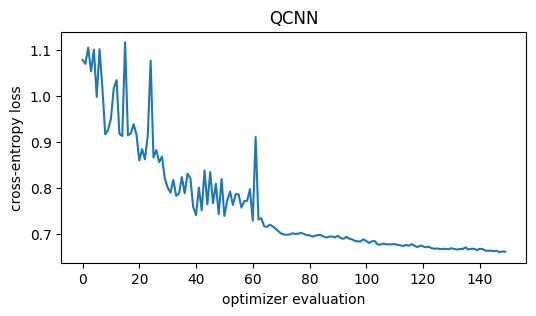

QCNN: test F1 = 0.7781 (465 s)


In [14]:
cb, hist = make_live_plot("QCNN")
qcnn = make_qcnn(QCNN_MAXITER, callback=cb)
t0 = time.time(); qcnn.fit(X_train, 2 * y_train - 1); t_qcnn = time.time() - t0     # labels as -1 / +1
y_pred_qcnn = (np.ravel(qcnn.predict(X_test)) > 0).astype(int)
print(f"QCNN: test F1 = {f1_score(y_test, y_pred_qcnn):.4f} ({t_qcnn:.0f} s)")

## 5e. Classical baselines

The paper compares against a random forest and an SVM from scikit-learn and a CNN in TensorFlow. Each baseline is trained twice:

- on the same 4 PCA angles the quantum models see, which isolates the effect of the model;
- on all flow features (standardised), which is what a practitioner would actually deploy.

The paper does not say which input its baselines used. Reporting both keeps the comparison honest.

In [15]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
import tensorflow as tf
tf.random.set_seed(SEED); tf.get_logger().setLevel("ERROR")

def cnn_classifier(n_features, n_classes):
    # CHOICE: small 1-D CNN; the paper does not give its architecture
    out, loss = (1, "binary_crossentropy") if n_classes == 2 else (n_classes, "sparse_categorical_crossentropy")
    model = tf.keras.Sequential([
        tf.keras.layers.Input((n_features, 1)),
        tf.keras.layers.Conv1D(16, 2, padding="same", activation="relu"),
        tf.keras.layers.Conv1D(16, 2, padding="same", activation="relu"),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(out, activation="sigmoid" if n_classes == 2 else "softmax")])
    model.compile(optimizer="adam", loss=loss)
    return model

def run_classical(Xtr, ytr, Xte, n_classes=2):
    preds = {}
    preds["RF"]  = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(Xtr, ytr).predict(Xte)
    preds["SVM"] = SVC(kernel="rbf", random_state=SEED).fit(Xtr, ytr).predict(Xte)
    cnn = cnn_classifier(Xtr.shape[1], n_classes)
    cnn.fit(Xtr[..., None], ytr, epochs=60, batch_size=32, verbose=0)
    p = cnn.predict(Xte[..., None], verbose=0)
    preds["CNN"] = (p.ravel() > 0.5).astype(int) if n_classes == 2 else p.argmax(1)
    return preds

classic_q = run_classical(X_train, y_train, X_test)                       # same 4 angles
full = StandardScaler().fit(X_train_raw)
classic_full = run_classical(full.transform(X_train_raw), y_train, full.transform(X_test_raw))
for k in classic_q:
    print(f"{k:4s} F1 on 4 PCA angles = {f1_score(y_test, classic_q[k]):.4f} | on all {len(FEATURES)} features = {f1_score(y_test, classic_full[k]):.4f}")

RF   F1 on 4 PCA angles = 0.9925 | on all 77 features = 0.9975
SVM  F1 on 4 PCA angles = 0.9724 | on all 77 features = 0.9901
CNN  F1 on 4 PCA angles = 0.9877 | on all 77 features = 0.9950


### Binary results next to the paper

The paper's numbers below are the CIC-IDS-2017 column of the binary-classification table in the conference version (QML-IDS, arXiv:2410.16308, Table IV). The journal version may report slightly different values. Differences are expected: the paper's sample sizes, feature reduction and iteration budgets are unknown, and this run uses far fewer flows.

In [ ]:
PAPER_BINARY_CICIDS17 = {"VQC (tuned)": 94.78, "QSVM": 94.40, "QCNN": 95.60, "RF": 92.45, "SVM": 93.78, "CNN": 93.15}

f1 = lambda p: 100 * f1_score(y_test, p)
binary = pd.DataFrame({
    "this notebook, 4 angles (%)": {"VQC (default)": f1(y_pred_vqc), "VQC (tuned)": f1(y_pred_best), "QSVM": f1(y_pred_qsvc), "QCNN": f1(y_pred_qcnn),
                                    **{k: f1(v) for k, v in classic_q.items()}},
    f"this notebook, all {len(FEATURES)} features (%)": {k: f1(v) for k, v in classic_full.items()},
    "paper, Table IV (%)": PAPER_BINARY_CICIDS17,
}).round(2)
display(binary)

ax = binary.plot.bar(figsize=(8, 3.5), rot=0, width=.8); ax.set_ylabel("F1 (%)")
ax.set_ylim(max(0, np.nanmin(binary.values) - 10), 100.5); ax.legend(loc="lower right", fontsize=8)
ax.set_title("BENIGN vs DDoS, CIC-IDS-2017"); plt.show()

## 6. From simulator to NISQ devices (paper Tables II–III)

The paper re-ran its models on five IBM devices (Cairo, Kyoto, Brisbane, Osaka, Sherbrooke) with transpiler optimisation levels 0–3, two Runtime resilience levels and dynamical decoupling on or off. Most of those machines have since been retired, so this section uses Qiskit's *fake* versions of the same five devices: each one carries a stored snapshot of that device's qubit layout, native gates, gate errors, readout errors and coherence times, and Aer turns the snapshot into a noise model.

The trained VQC weights are kept fixed; only inference runs on the noisy devices. For each device the cell measures test F1 under:

- **optimisation levels 0–3**: how hard the transpiler works to shorten the circuit after mapping it onto the device's qubit graph and native gates;
- **dynamical decoupling (DD)**: X–X pulse pairs inserted into idle periods to refocus dephasing;
- **readout correction (RO)**: inverting each qubit's measured confusion matrix. On IBM Runtime the Estimator's `resilience_level=1` applies a related readout technique (TREX); the paper's resilience setting is approximated here, not reproduced.

In [ ]:
from qiskit_ibm_runtime.fake_provider import FakeCairoV2, FakeKyoto, FakeBrisbane, FakeOsaka, FakeSherbrooke

# Noise study uses the default ZZ VQC unless the tuned model's feature map can be transpiled with free parameters
noisy_model = vqc_best if BEST.feature_map != "RawFeatureVector" else vqc
fm_n, an_n = noisy_model.feature_map, noisy_model.ansatz
logical = fm_n.compose(an_n); logical.measure_all()
Xn, yn = X_test[:NOISY_N_TEST], y_test[:NOISY_N_TEST]

def parity_p1(probs):
    # probability of odd parity (class 1) from a 2^n probability vector indexed by bitstring integer
    # Qiskit's VQC assigns outcome integer k to class k % 2 (the value of the qubit-0 bit)
    return probs[np.arange(len(probs)) % 2 == 1].sum()

def readout_matrix(backend, isa):
    # Tensor product of single-qubit confusion matrices for the physical qubits the circuit was mapped to
    phys = isa.layout.final_index_layout()[:fm_n.num_qubits]
    A = np.array([[1.0]])
    for q in phys:                                  # qubit 0 is the least significant bit, so it goes last
        e = backend.target["measure"][(q,)].error or 0.0
        A = np.kron(np.array([[1 - e, e], [e, 1 - e]]), A)
    return A

def device_target(backend):
    # FakeCairoV2's stored calibration lists CX on some couplers and ECR on others, a mix the transpiler
    # cannot orient. For such devices, transpile onto the ECR couplers only; noise still comes from the full snapshot.
    t = backend.target
    if not {"cx", "ecr"} <= set(t.operation_names):
        return t
    reduced = Target(num_qubits=t.num_qubits, dt=t.dt, description=f"{backend.name}, ECR couplers only")
    for name in ["ecr", "rz", "sx", "x", "id", "measure", "delay", "reset"]:
        if name in t.operation_names:
            reduced.add_instruction(t.operation_from_name(name), dict(t[name]), name=name)
    return reduced

def noisy_f1(backend, opt_level, dd=False, ro=False):
    target = device_target(backend)
    # Level 0 places virtual qubit i on physical qubit i. On devices whose stored calibration marks some
    # couplers as broken, qubits 0..3 are not connected, so level 0 then reuses the level-1 placement.
    try:
        pm = generate_preset_pass_manager(optimization_level=opt_level, target=target, seed_transpiler=SEED)
        pm.run(logical)
    except Exception:
        layout = generate_preset_pass_manager(optimization_level=1, target=target, seed_transpiler=SEED).run(logical).layout
        pm = generate_preset_pass_manager(optimization_level=opt_level, target=target, seed_transpiler=SEED,
                                          initial_layout=layout.initial_index_layout()[:logical.num_qubits])
    if dd:
        pm.scheduling = PassManager([ALAPScheduleAnalysis(target=target),
                                     PadDynamicalDecoupling(target=target, dd_sequence=[XGate(), XGate()])])
    isa = pm.run(logical)
    values = {**{p: Xn[:, i] for i, p in enumerate(fm_n.parameters)},
              **{p: np.full(len(Xn), w) for p, w in zip(an_n.parameters, noisy_model.weights)}}
    binds = np.column_stack([values[p] for p in isa.parameters])
    sampler = AerSampler.from_backend(backend, default_shots=SHOTS, seed=SEED)
    data = sampler.run([(isa, binds)]).result()[0].data.meas
    A_inv = np.linalg.pinv(readout_matrix(backend, isa)) if ro else None
    preds = []
    for i in range(len(Xn)):
        counts = data[i].get_counts()
        probs = np.zeros(2 ** fm_n.num_qubits)
        for bits, c in counts.items():
            probs[int(bits, 2)] += c
        probs /= probs.sum()
        if ro:
            probs = np.clip(A_inv @ probs, 0, None); probs /= probs.sum()
        preds.append(int(parity_p1(probs) >= 0.5))
    two_q = sum(v for k, v in isa.count_ops().items() if k in ("ecr", "cz", "cx"))
    return 100 * f1_score(yn, preds), isa.depth(), two_q

ideal = 100 * f1_score(yn, noisy_model.predict(Xn))
rows = []
for backend in [FakeCairoV2(), FakeKyoto(), FakeBrisbane(), FakeOsaka(), FakeSherbrooke()]:
    row = {"device": backend.name.replace("fake_", "ibm_")}
    for lvl in range(4):
        row[f"opt {lvl}"], depth, twoq = noisy_f1(backend, lvl)
        if lvl == 3: row["depth (opt 3)"], row["2q gates (opt 3)"] = depth, twoq
    row["opt 3 + DD"] = noisy_f1(backend, 3, dd=True)[0]
    row["opt 3 + DD + RO"] = noisy_f1(backend, 3, dd=True, ro=True)[0]
    rows.append(row); print(row["device"], "done", flush=True)

noisy_df = pd.DataFrame(rows).set_index("device").round(2)
print(f"noiseless Aer simulator, same {len(Xn)} flows: F1 = {ideal:.2f} %")
display(noisy_df)

### Optional: the same circuit on a real IBM device

This cell only runs if you paste an IBM Quantum Platform API key into `IBM_TOKEN` in the configuration cell (the open plan includes a monthly free allowance). It sends the test flows as one batched job to the least busy device with dynamical decoupling and measurement twirling switched on. Queue times vary from seconds to hours.

In [ ]:
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as RuntimeSampler
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN, instance=IBM_INSTANCE)
    hw = service.least_busy(operational=True, simulator=False)
    print("running on", hw.name)
    isa = generate_preset_pass_manager(optimization_level=3, backend=hw, seed_transpiler=SEED).run(logical)
    values = {**{p: Xn[:, i] for i, p in enumerate(fm_n.parameters)},
              **{p: np.full(len(Xn), w) for p, w in zip(an_n.parameters, noisy_model.weights)}}
    binds = np.column_stack([values[p] for p in isa.parameters])
    sampler = RuntimeSampler(mode=hw)
    sampler.options.default_shots = SHOTS
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XX"
    sampler.options.twirling.enable_measure = True
    job = sampler.run([(isa, binds)]); print("job id:", job.job_id())
    data = job.result()[0].data.meas
    preds = []
    for i in range(len(Xn)):
        counts = data[i].get_counts(); total = sum(counts.values())
        preds.append(int(sum(c for b, c in counts.items() if int(b, 2) % 2 == 1) / total >= 0.5))
    print(f"{hw.name}: F1 = {100 * f1_score(yn, preds):.2f} %")
else:
    print("IBM_TOKEN is empty; skipping real hardware.")

## 7. Multiclass: which attack is it? (paper Table VI)

After detection, the paper classifies the attack family. For CIC-IDS-2017 it reports per-class F1 for seven families. This section downloads the remaining attack days (about 710 MB; Monday holds only benign traffic and is skipped) and groups CIC-IDS-2017's fourteen attack labels into those seven families:

| Family | CIC-IDS-2017 labels |
|---|---|
| BoT | Bot |
| BruteForce | FTP-Patator, SSH-Patator |
| DoS | DoS Hulk, DoS GoldenEye, DoS slowloris, DoS Slowhttptest, Heartbleed |
| DDoS | DDoS |
| Infiltration | Infiltration |
| PortScan | PortScan |
| WebAttack | Web Attack – Brute Force, XSS, Sql Injection |

Placing Heartbleed (11 flows) under DoS is this notebook's choice. Infiltration has only 36 flows in the whole dataset, so its test set is tiny and its F1 will swing between runs.

The VQC handles seven classes the same way it handles two: each 4-bit outcome is assigned to class `outcome mod 7`, and the loss is cross-entropy over the seven class probabilities. The QCNN has a single output, so it is trained one-vs-rest (seven binary QCNNs, highest score wins).

In [ ]:
ATTACK_DAYS = ["Tuesday-WorkingHours.pcap_ISCX.csv",
               "Wednesday-workingHours.pcap_ISCX.csv",
               "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
               "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
               "Friday-WorkingHours-Morning.pcap_ISCX.csv",
               "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
               "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"]

def attack_family(label):
    if label == "Bot": return "BoT"
    if label in ("FTP-Patator", "SSH-Patator"): return "BruteForce"
    if label == "DDoS": return "DDoS"
    if label.startswith("DoS") or label == "Heartbleed": return "DoS"
    if label == "Infiltration": return "Infiltration"
    if label == "PortScan": return "PortScan"
    if label.startswith("Web Attack"): return "WebAttack"
    return None                                                   # BENIGN

if RUN_MULTICLASS:
    parts = []
    for fname in ATTACK_DAYS:
        day = load_flows(download(fname))
        day["Family"] = day["Label"].map(attack_family)
        parts.append(day.dropna(subset=["Family"]))
    attacks = pd.concat(parts, ignore_index=True)
    MC_FEATURES = [c for c in attacks.columns if c not in ("Label", "Family") and attacks[c].notna().all()]
    print(attacks["Family"].value_counts().to_string())

In [ ]:
if RUN_MULTICLASS:
    mc = pd.concat([g.sample(min(len(g), MC_PER_CLASS), random_state=SEED) for _, g in attacks.groupby("Family")])
    FAMILIES = sorted(mc["Family"].unique())
    Xm_raw = mc[MC_FEATURES].to_numpy(float)
    ym = mc["Family"].map({f: i for i, f in enumerate(FAMILIES)}).to_numpy()
    Xm_tr_raw, Xm_te_raw, ym_tr, ym_te = train_test_split(Xm_raw, ym, test_size=0.4, stratify=ym, random_state=SEED)

    to_q_mc = make_pipeline(StandardScaler(), PCA(N_QUBITS, random_state=SEED), MinMaxScaler((0, np.pi)))
    Xm_tr = to_q_mc.fit_transform(Xm_tr_raw); Xm_te = np.clip(to_q_mc.transform(Xm_te_raw), 0, np.pi)
    print("train", Xm_tr.shape, "test", Xm_te.shape, "| test flows per family:",
          dict(zip(FAMILIES, np.bincount(ym_te))))

    mc_pred = {}
    # VQC (same tuned configuration as the binary task)
    cb, _ = make_live_plot("Multiclass VQC")
    vqc_mc = make_vqc(BEST.feature_map, BEST.ansatz, BEST.optimizer, MC_VQC_MAXITER, callback=cb)
    t0 = time.time(); vqc_mc.fit(Xm_tr, ym_tr); print(f"VQC trained in {time.time() - t0:.0f} s")
    mc_pred["VQC"] = vqc_mc.predict(Xm_te)

    # QSVM (scikit-learn SVC handles multiclass one-vs-one)
    qsvc_mc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=build_feature_map(kernel_fm_name)), random_state=SEED)
    mc_pred["QSVM"] = qsvc_mc.fit(Xm_tr, ym_tr).predict(Xm_te)

In [ ]:
if RUN_MULTICLASS and RUN_QCNN_MULTICLASS:
    scores = np.zeros((len(Xm_te), len(FAMILIES)))
    for k, fam in enumerate(FAMILIES):
        t0 = time.time()
        m = make_qcnn(MC_QCNN_MAXITER)
        m.fit(Xm_tr, np.where(ym_tr == k, 1, -1))
        scores[:, k] = np.ravel(m.neural_network.forward(Xm_te, m.weights))   # <Z> score, higher = this family
        print(f"QCNN one-vs-rest: {fam} done ({time.time() - t0:.0f} s)", flush=True)
    mc_pred["QCNN"] = scores.argmax(1)

In [ ]:
if RUN_MULTICLASS:
    mc_pred.update(run_classical(Xm_tr, ym_tr, Xm_te, n_classes=len(FAMILIES)))

    PAPER_MC_CICIDS17 = pd.DataFrame({   # QML-IDS (arXiv:2410.16308), Table VI, F1 in %
        "VQC":  [88.23, 95.87, 90.54, 90.32, 90.99, 95.45, 92.78],
        "QSVM": [97.11, 99.99, 99.99, 90.79, 99.66, 96.32, 96.67],
        "QCNN": [98.45, 99.99, 96.55, 92.45, 97.42, 97.48, 97.83],
        "RF":   [92.12, 96.24, 99.34, 98.02, 97.53, 97.45, 96.89],
        "SVM":  [94.67, 93.45, 94.32, 99.67, 99.87, 97.89, 98.21],
        "CNN":  [91.45, 94.42, 96.32, 96.15, 97.15, 96.88, 96.55],
    }, index=["BoT", "BruteForce", "DDoS", "DoS", "Infiltration", "PortScan", "WebAttack"])

    ours = pd.DataFrame({m: 100 * f1_score(ym_te, p, average=None, labels=range(len(FAMILIES)), zero_division=0)
                         for m, p in mc_pred.items()}, index=FAMILIES).round(2)
    ours.loc["macro avg"] = ours.mean().round(2)
    print("Per-family F1 (%), this notebook, 4 PCA angles for every model")
    display(ours)
    print("Per-family F1 (%) reported in the paper")
    display(PAPER_MC_CICIDS17)

    ConfusionMatrixDisplay(confusion_matrix(ym_te, mc_pred["VQC"]), display_labels=FAMILIES).plot(
        cmap="Blues", xticks_rotation=45, colorbar=False)
    plt.title("Multiclass VQC"); plt.show()

## Reading the results

Some points to raise with students, whatever numbers your run produces:

- **The quantum models see 4 numbers per flow.** PCA compresses dozens of flow statistics into as many angles as there are qubits. Compare the classical baselines on the same 4 angles with the same baselines on all features: the gap measures what the qubit budget costs, independent of whether the model is quantum.
- **Simulation is not speed-up.** Every quantum result here was computed by a classical simulator. A 4-qubit circuit is easy to simulate, so these experiments cannot show a quantum advantage; they show that the hybrid pipeline works end to end.
- **Training cost differs sharply between optimisers.** COBYLA and SPSA need one or two circuit evaluations per step. ADAM and GradientDescent need parameter-shift gradients, which on a 16-parameter ansatz is 32 extra circuits per sample per step. The hyperparameter table records the wall-clock times.
- **Noise.** The fake-device table shows how much F1 survives the move from the ideal simulator to calibrated device noise, and how much the transpiler level, dynamical decoupling and readout correction recover.
- **Sample size.** The paper does not say how many flows it trained on. This notebook uses a few hundred per task, so expect run-to-run variation of a few points, especially for the small classes in the multiclass task.